In [147]:
#Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

In [148]:
df=pd.read_csv("../data/cleaned/cleaned_railway.csv")

Checking outliers

In [149]:
Q1 = df["Price"].quantile(0.25)
Q3 = df["Price"].quantile(0.75)
IQR = Q3 - Q1
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

price_outlier= df[(df["Price"]<lower_bound) |(df["Price"]>upper_bound)]
print("NUMBER OF OUTLIERS",len(price_outlier))

Q1: 5.0
Q3: 35.0
IQR: 30.0
Lower bound: -40.0
Upper bound: 80.0
NUMBER OF OUTLIERS 1555


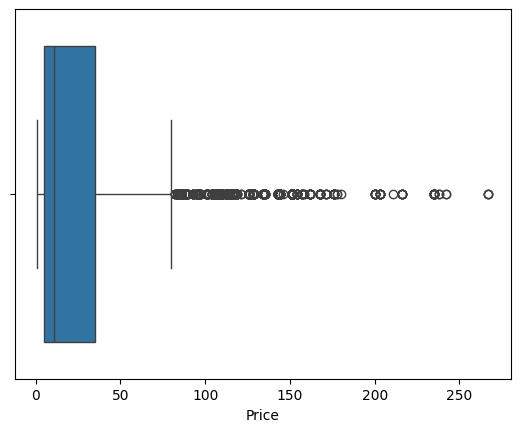

In [150]:
price_outlier= sns.boxplot(x=df["Price"])


Investigating whether the outliers are normal or not

In [151]:
price_outlier= df[(df["Price"]<lower_bound) |(df["Price"]>upper_bound)]
outlier_summary=(price_outlier.groupby(["Ticket Type"])["Price"].agg(["count", "min", "median", "max"]))
print(outlier_summary)

             count  min  median  max
Ticket Type                         
Advance        291   84    86.0  135
Anytime        684   86   144.0  267
Off-Peak       580   82   113.0  203


In [152]:
print(price_outlier.nlargest(20,"Price")[["Price","Ticket Type","Departure Station","Arrival Destination"]].to_string(index=False))

 Price Ticket Type     Departure Station   Arrival Destination
   267     Anytime Manchester Piccadilly         London Euston
   267     Anytime Manchester Piccadilly         London Euston
   267     Anytime Manchester Piccadilly         London Euston
   242     Anytime               Reading Liverpool Lime Street
   242     Anytime               Reading Liverpool Lime Street
   238     Anytime Liverpool Lime Street     London Paddington
   238     Anytime Liverpool Lime Street     London Paddington
   235     Anytime Liverpool Lime Street         London Euston
   235     Anytime Liverpool Lime Street         London Euston
   235     Anytime Liverpool Lime Street         London Euston
   235     Anytime Liverpool Lime Street         London Euston
   235     Anytime Liverpool Lime Street         London Euston
   235     Anytime Liverpool Lime Street         London Euston
   235     Anytime Liverpool Lime Street         London Euston
   235     Anytime Liverpool Lime Street         London

### Price Outlier Detection

The IQR method was initially applied to the overall Price column, identifying 1,555 potential outliers using an upper bound of £80.

A second analysis was performed by grouping records according to Ticket Class and Ticket Type. This identified 3,210 potential outliers across the six groups.

The group-wise analysis revealed different upper bounds for each ticket category. Standard Off-Peak had the highest outlier percentage (18.76%).

**Treatment decision:** No records were removed or modified solely based on the IQR results. Potential outliers will be investigated further to distinguish legitimate ticket prices from possible data errors.

In [153]:
def count_iqr_outliers(group):
    Q1 = group["Price"].quantile(0.25)
    Q3 = group["Price"].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = ((group["Price"] < lower_bound) | (group["Price"] > upper_bound)).sum()

    return pd.Series({
        "Total Tickets": len(group),
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Upper Bound": upper_bound,
        "Lower Bound": lower_bound,
        "Outlier Count": outlier_count
    })

group_outlier = df.groupby(["Ticket Type"]).apply(count_iqr_outliers, include_groups=False).round(2)
print(group_outlier)

             Total Tickets   Q1    Q3   IQR  Upper Bound  Lower Bound  \
Ticket Type                                                             
Advance            17561.0  4.0  23.0  19.0         51.5        -24.5   
Anytime             5340.0  9.0  67.0  58.0        154.0        -78.0   
Off-Peak            8752.0  7.0  35.0  28.0         77.0        -35.0   

             Outlier Count  
Ticket Type                 
Advance             1610.0  
Anytime               66.0  
Off-Peak             723.0  


In [154]:
def flag_group_outliers(group):
    Q1 = group["Price"].quantile(0.25)
    Q3 = group["Price"].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    group = group.copy()

    group["Lower Bound"] = lower_bound
    group["Upper Bound"] = upper_bound

    group["Is Outlier"] = ((group["Price"] < lower_bound) | (group["Price"] > upper_bound) )

    return group


df_checked = (df.groupby(["Ticket Type"], group_keys=False)
      .apply(flag_group_outliers))

price_outliers_grouped = df_checked[df_checked["Is Outlier"]]

print("Number of potential outliers:", len(price_outliers_grouped))

print( price_outliers_grouped[ ["Ticket Type", "Price", "Lower Bound", "Upper Bound"] ].sort_values("Price", ascending=False).head(20)
)

Number of potential outliers: 2399
      Ticket Type  Price  Lower Bound  Upper Bound
11849     Anytime    267        -78.0        154.0
711       Anytime    267        -78.0        154.0
2042      Anytime    267        -78.0        154.0
31434     Anytime    242        -78.0        154.0
13367     Anytime    242        -78.0        154.0
22488     Anytime    238        -78.0        154.0
20279     Anytime    238        -78.0        154.0
30508     Anytime    235        -78.0        154.0
29422     Anytime    235        -78.0        154.0
2041      Anytime    235        -78.0        154.0
2046      Anytime    235        -78.0        154.0
26391     Anytime    235        -78.0        154.0
13658     Anytime    235        -78.0        154.0
8862      Anytime    235        -78.0        154.0
709       Anytime    235        -78.0        154.0
148       Anytime    235        -78.0        154.0
17563     Anytime    235        -78.0        154.0
17564     Anytime    235        -78.0        15

C:\Users\Nour\AppData\Local\Temp\ipykernel_17032\3972748408.py:21: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(flag_group_outliers))


In [155]:
group_outlier["Outlier Percentage"] = (group_outlier["Outlier Count"] / group_outlier["Total Tickets"] * 100).round(2)

print(group_outlier)

             Total Tickets   Q1    Q3   IQR  Upper Bound  Lower Bound  \
Ticket Type                                                             
Advance            17561.0  4.0  23.0  19.0         51.5        -24.5   
Anytime             5340.0  9.0  67.0  58.0        154.0        -78.0   
Off-Peak            8752.0  7.0  35.0  28.0         77.0        -35.0   

             Outlier Count  Outlier Percentage  
Ticket Type                                     
Advance             1610.0                9.17  
Anytime               66.0                1.24  
Off-Peak             723.0                8.26  


### Investigation of Price Outliers

Potential outliers in the Standard – Off-Peak group were
investigated by comparing prices across individual routes.

Two routes were examined:

- Manchester Piccadilly to London Paddington:
  59 tickets were found, all priced at £128.

- Birmingham New Street to Reading:
  29 tickets were found, all priced at £50.

The repeated and consistent prices within these routes
suggest that the flagged values may reflect route-related
pricing patterns rather than obvious data-entry errors.

No prices were removed or modified based on this
investigation.

In [156]:
# Get all numerical columns
numeric_columns = df.select_dtypes(include="number").columns

print("Numerical columns:")
print(numeric_columns)

print("\nSummary statistics:")
print(df[numeric_columns].describe())

Numerical columns:
Index(['Price'], dtype='object')

Summary statistics:
              Price
count  31653.000000
mean      23.439200
std       29.997628
min        1.000000
25%        5.000000
50%       11.000000
75%       35.000000
max      267.000000


In [157]:
time_columns = [
    "Journey Datetime",
    "Arrival Time",
    "Actual Arrival Time"
]

for col in time_columns:
    print(f"\n{col}")
    print("Data type:", df[col].dtype)
    print("Missing values:", df[col].isna().sum())
    print("Sample values:")
    print(df[col].head())


Journey Datetime
Data type: object
Missing values: 0
Sample values:
0    2024-01-01 11:00:00
1    2024-01-01 09:45:00
2    2024-01-02 18:15:00
3    2024-01-01 21:30:00
4    2024-01-01 16:45:00
Name: Journey Datetime, dtype: object

Arrival Time
Data type: object
Missing values: 0
Sample values:
0    13:30:00
1    11:35:00
2    18:45:00
3    22:30:00
4    19:00:00
Name: Arrival Time, dtype: object

Actual Arrival Time
Data type: object
Missing values: 1880
Sample values:
0    13:30:00
1    11:40:00
2    18:45:00
3    22:30:00
4    19:00:00
Name: Actual Arrival Time, dtype: object


DELAY

In [158]:

sched  = pd.to_timedelta(df["Arrival Time"])
actual = pd.to_timedelta(df["Actual Arrival Time"])

df["delay_min"] = (actual - sched).dt.total_seconds() / 60


print(df["delay_min"].describe())
print(df.groupby("Journey Status")["delay_min"].describe())

count    29773.000000
mean         3.249689
std         14.770539
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        180.000000
Name: delay_min, dtype: float64
                  count       mean        std  min   25%   50%   75%    max
Journey Status                                                             
Cancelled           0.0        NaN        NaN  NaN   NaN   NaN   NaN    NaN
Delayed          2292.0  42.213351  34.491193  0.0  19.0  37.0  53.0  180.0
On Time         27481.0   0.000000   0.000000  0.0   0.0   0.0   0.0    0.0


In [159]:
delayed=df[df["Journey Status"]=="Delayed"]
Q1=delayed['delay_min'].quantile(0.25)
Q3=delayed['delay_min'].quantile(0.75)
IQR=Q3-Q1
upper_bound=Q3+1.5*IQR
print("Q1:",Q1)
print("Q3:",Q3)
print("IQR:",IQR)
print("Upper bound:",upper_bound)
delay_outliers=delayed[delayed['delay_min']>upper_bound]
print("Number of potential outliers:",len(delay_outliers))
print("Biggest delay:",delayed['delay_min'].max())

Q1: 19.0
Q3: 53.0
IQR: 34.0
Upper bound: 104.0
Number of potential outliers: 130
Biggest delay: 180.0


In [160]:
delay_outliers=delay_outliers.copy()
delay_outliers["route"]=delay_outliers["Departure Station"]+"->"+delay_outliers["Arrival Destination"]
print(delay_outliers["route"].value_counts())# to know on which route the delay of the 130 outliers take place
print(delay_outliers["Reason for Delay"].value_counts()) #to count the numbers delay for each reason
print("Distinct trains:",delay_outliers.groupby(["route","Journey Datetime"]).ngroups)

route
Manchester Piccadilly->Liverpool Lime Street    74
Manchester Piccadilly->Leeds                    56
Name: count, dtype: int64
Reason for Delay
Signal Failure    77
Staff Shortage    53
Name: count, dtype: int64
Distinct trains: 80


In [161]:
delayed= delayed.copy()
delayed["route"] = delayed["Departure Station"] + " -> " + delayed["Arrival Destination"]
per_train = delayed.groupby(["route", "Journey Datetime"])["delay_min"].nunique()
print("Delayed trains:", len(per_train))
print("Trains whose tickets disagree on the delay:", (per_train > 1).sum())

Delayed trains: 1062
Trains whose tickets disagree on the delay: 0


In [162]:
df

,Purchase Type,Payment Method,Railcard,Ticket Type,Price,Departure Station,Arrival Destination,Arrival Time,Actual Arrival Time,Journey Status,Reason for Delay,Refund Request,Purchase Datetime,Journey Datetime,delay_min
0,Online,Contactless,Adult,Advance,43,London Paddington,Liverpool Lime Street,13:30:00,13:30:00,On Time,No Delay,No,2023-12-08 12:41:11,2024-01-01 11:00:00,0.0
1,Station,Credit Card,Adult,Advance,23,London Kings Cross,York,11:35:00,11:40:00,Delayed,Signal Failure,No,2023-12-16 11:23:01,2024-01-01 09:45:00,5.0
2,Online,Credit Card,No Railcard,Advance,3,Liverpool Lime Street,Manchester Piccadilly,18:45:00,18:45:00,On Time,No Delay,No,2023-12-19 19:51:27,2024-01-02 18:15:00,0.0
3,Station,Credit Card,No Railcard,Advance,13,London Paddington,Reading,22:30:00,22:30:00,On Time,No Delay,No,2023-12-20 23:00:36,2024-01-01 21:30:00,0.0
4,Online,Contactless,No Railcard,Advance,76,Liverpool Lime Street,London Euston,19:00:00,19:00:00,On Time,No Delay,No,2023-12-27 18:22:56,2024-01-01 16:45:00,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31648,Online,Credit Card,No Railcard,Off-Peak,4,Manchester Piccadilly,Liverpool Lime Street,20:30:00,20:30:00,On Time,No Delay,No,2024-04-30 18:42:58,2024-04-30 20:00:00,0.0
31649,Online,Contactless,No Railcard,Off-Peak,10,London Euston,Birmingham New Street,21:35:00,21:35:00,On Time,No Delay,No,2024-04-30 18:46:10,2024-04-30 20:15:00,0.0
31650,Station,Credit Card,No Railcard,Off-Peak,4,Manchester Piccadilly,Liverpool Lime Street,20:45:00,20:45:00,On Time,No Delay,No,2024-04-30 18:56:41,2024-04-30 20:15:00,0.0
31651,Station,Credit Card,No Railcard,Off-Peak,10,London Euston,Birmingham New Street,22:35:00,22:35:00,On Time,No Delay,No,2024-04-30 19:51:47,2024-04-30 21:15:00,0.0


In [163]:
df["flag_extreme_delay"] = (df["delay_min"] > upper_bound)
print(df["flag_extreme_delay"].sum())

130


130 delays exceeded the IQR upper bound (104 min). They were retained: they are concentrated on two routes and two causes, and are consistent across tickets on the same train. They cannot be confirmed as real events without the data owner, so they are flagge

In [164]:
df["flag_delayed_zero_min"] = (df["Journey Status"] == "Delayed") & (df["delay_min"] == 0)
print(df["flag_delayed_zero_min"].sum())

18


18 journeys are labelled Delayed but arrived exactly on schedule. It cannot be determined from the data which field is wrong, so they were flagged and left unchanged


LEAD HOURS : DIFFERENCE BTW PURCHASING TIOME AND JOURNEY TIME

In [165]:
df["Journey Datetime"] = pd.to_datetime(df["Journey Datetime"])
df["Purchase Datetime"] = pd.to_datetime(df["Purchase Datetime"])

In [166]:
df["lead_hours"]=(df["Journey Datetime"]-df["Purchase Datetime"]).dt.total_seconds()/3600
print(df["lead_hours"].describe())
print("Purchased after departure:", (df["lead_hours"]<0).sum())

count    31653.000000
mean        39.827380
std         92.121621
min          0.250556
25%          1.390556
50%         22.269722
75%         22.440556
max        687.641944
Name: lead_hours, dtype: float64
Purchased after departure: 0


There is a concentration btw 22.5 hr and21 hr which isnot normal , so we would check the hours across the ticket types  

In [167]:
Q1 = df["lead_hours"].quantile(0.25)
Q3 = df["lead_hours"].quantile(0.75)
IQR = Q3 - Q1
upper = Q3 + 1.5 * IQR
lower = Q1 - 1.5 * IQR
print("Q1:", Q1, "Q3:", Q3, "IQR:", IQR, "LOWER:", lower, "UPPER:", upper)
print("Above upper:", (df["lead_hours"] > upper).sum())

Q1: 1.3905555555555555 Q3: 22.440555555555555 IQR: 21.05 LOWER: -30.18444444444445 UPPER: 54.01555555555556
Above upper: 3520


In [168]:
for t, g in df.groupby("Ticket Type"):
    q1, q3 = g["lead_hours"].quantile([0.25, 0.75])
    iqr = q3 - q1
    upper = q3 + 1.5 * iqr
    above = (g["lead_hours"] > upper).sum()
    pct = above / len(g) * 100
    print(t, "| Q1:", round(q1, 2), "| Q3:", round(q3, 2), "| IQR:", round(iqr, 2),
          "| upper:", round(upper, 1), "| above:", above, "of", len(g),
          "| pct:", round(pct, 1), "%")

Advance | Q1: 22.32 | Q3: 23.42 | IQR: 1.1 | upper: 25.1 | above: 4200 of 17561 | pct: 23.9 %
Anytime | Q1: 1.29 | Q3: 1.45 | IQR: 0.16 | upper: 1.7 | above: 329 of 5340 | pct: 6.2 %
Off-Peak | Q1: 1.31 | Q3: 1.45 | IQR: 0.14 | upper: 1.7 | above: 615 of 8752 | pct: 7.0 %


In [169]:
adv = df[df["Ticket Type"] == "Advance"]
print((adv["lead_hours"] / 24).round().value_counts().sort_index().head(10))

lead_hours
0.0      456
1.0    12914
2.0      671
3.0      348
4.0      247
5.0      227
6.0      213
7.0      255
8.0      213
9.0      187
Name: count, dtype: int64


In [170]:
df["flag_advance_lt12h"] = (df["Ticket Type"] == "Advance") & (df["lead_hours"] < 12)

print(df["flag_advance_lt12h"].sum())

456


The percentage of flagged tickets was computed per ticket type as the number of tickets above the IQR upper bound divided by the total tickets of that type: 23.9% for Advance, 6.2% for Anytime and 7.0% for Off-Peak. The high Advance share reflects the tight clustering of its lead times (IQR of about 1.1 hours) rather than data errors, so no records were removed on this basis. Only 456 Advance tickets purchased less than 12 hours before departure were flagged (flag_advance_lt12h) for confirmation with the data owner, and the original values were left unchanged.

Duration



In [171]:
dep = df["Journey Datetime"] - df["Journey Datetime"].dt.normalize()

arr = pd.to_timedelta(df["Arrival Time"])

df["duration_min"] = (arr - dep).dt.total_seconds() / 60


print("Overnight journeys:", (df["duration_min"] < 0).sum())

df.loc[df["duration_min"] < 0, "duration_min"] += 1440

Overnight journeys: 961


In [172]:
print(df["duration_min"].describe())
print("Duration <= 0:", (df["duration_min"] <= 0).sum())
print("Duration > 12 hours:", (df["duration_min"] > 720).sum())

count    31653.000000
mean        71.154235
std         36.330811
min         15.000000
25%         30.000000
50%         80.000000
75%         90.000000
max        270.000000
Name: duration_min, dtype: float64
Duration <= 0: 0
Duration > 12 hours: 0


In [173]:
df["route"] = df["Departure Station"] + " -> " + df["Arrival Destination"]
route_dur = df.groupby("route")["duration_min"].nunique()
print("Routes:", len(route_dur))
print("Routes with more than one duration:", (route_dur > 1).sum())

Routes: 65
Routes with more than one duration: 0


In [174]:
route_table = df.groupby("route").agg(
    n=("route", "size"),
    duration=("duration_min", "first"),
    median_price=("Price", "median")
).sort_values("duration")

print(route_table.to_string())

                                                   n  duration  median_price
route                                                                       
Birmingham New Street -> Wolverhampton            32      15.0           1.5
Reading -> Didcot                                 48      15.0           4.0
Birmingham New Street -> Nuneaton                219      20.0           7.0
Birmingham New Street -> Coventry                 65      20.0           4.0
Manchester Piccadilly -> Warrington               15      20.0           4.0
Birmingham New Street -> Tamworth                227      20.0           8.0
Bristol Temple Meads -> Cardiff Central           16      25.0           5.0
Reading -> London Paddington                     148      25.0          13.0
Reading -> Oxford                                122      25.0           6.0
York -> Leeds                                     17      25.0           5.0
York -> Wakefield                                 15      25.0           7.0

In [175]:
r = df[df["route"] == "London Paddington -> London Waterloo"]

print("Rows:", len(r))
print("Duration:", r["duration_min"].unique())
print("Price (min / median / max):", r["Price"].min(), r["Price"].median(), r["Price"].max())
print(r["Ticket Type"].value_counts())

Rows: 68
Duration: [90.]
Price (min / median / max): 3 5.0 11
Ticket Type
Advance     29
Anytime     25
Off-Peak    14
Name: count, dtype: int64


A London Paddington to London Waterloo route has a scheduled duration of 90 minutes, which is implausible for two London stations. The 68 rows were flagged for confirmation with the data owner and left unchanged.

In [176]:
df["flag_london_to_london"] = (df["route"] == "London Paddington -> London Waterloo")
print(df["flag_london_to_london"].sum())

68


Feature Engineering

Extracting , Day,Month,Hr, weekend

In [177]:

df["day_of_week"] = df["Journey Datetime"].dt.day_name()

df["month"] = df["Journey Datetime"].dt.month

df["hour"] = df["Journey Datetime"].dt.hour

df["is_weekend"] = df["Journey Datetime"].dt.dayofweek >= 5

In [178]:
print(df.loc[0, ["Journey Datetime", "day_of_week", "month", "hour", "is_weekend"]])

Journey Datetime    2024-01-01 11:00:00
day_of_week                      Monday
month                                 1
hour                                 11
is_weekend                        False
Name: 0, dtype: object


In [179]:
print(df["is_weekend"].value_counts())
print(df["month"].value_counts().sort_index())

is_weekend
False    22666
True      8987
Name: count, dtype: int64
month
1    8111
2    7644
3    8117
4    7781
Name: count, dtype: int64


In [180]:
print("Rows:", len(df))
print("Missing Journey Datetime:", df["Journey Datetime"].isna().sum())
print("Min date:", df["Journey Datetime"].min())
print("Max date:", df["Journey Datetime"].max())

Rows: 31653
Missing Journey Datetime: 0
Min date: 2024-01-01 00:00:00
Max date: 2024-04-30 23:45:00


Revenue Per Ticket and Per Ride

In [181]:
# 1) revenue per ticket
df["revenue_per_ticket"] = df["Price"]

# 2) revenue per ride
df["revenue_per_ride"] = df.groupby(["route", "Journey Datetime"])["Price"].transform("sum")

# 3) no. of ticket sold
df["tickets_on_ride"] = df.groupby(["route", "Journey Datetime"])["Price"].transform("size")

print(df[["revenue_per_ticket", "revenue_per_ride", "tickets_on_ride"]].describe().round(1))
print(df.loc[0, ["route", "Journey Datetime", "Price", "revenue_per_ride", "tickets_on_ride"]])

       revenue_per_ticket  revenue_per_ride  tickets_on_ride
count             31653.0           31653.0          31653.0
mean                 23.4              69.2              2.6
std                  30.0             153.0              2.2
min                   1.0               1.0              1.0
25%                   5.0               8.0              1.0
50%                  11.0              22.0              2.0
75%                  35.0              70.0              3.0
max                 267.0            1973.0             15.0
route               London Paddington -> Liverpool Lime Street
Journey Datetime                           2024-01-01 11:00:00
Price                                                       43
revenue_per_ride                                            43
tickets_on_ride                                              1
Name: 0, dtype: object


In [182]:
print(df.groupby(["route", "Journey Datetime"]).ngroups)

19871


In [183]:
df["Price"].sum()

np.int64(741921)

Seven features were engineered: day of week, month, hour, weekend flag, scheduled journey duration (minutes), delay (minutes), and revenue per ticket and per ride (gross, before refunds). All were complete except delay, which is missing for the 1,880 cancelled journeys because they have no actual arrival time; these were left blank by design.



In [184]:
new_cols = ["day_of_week", "month", "hour", "is_weekend", "duration_min",
            "delay_min", "revenue_per_ticket", "revenue_per_ride", "tickets_on_ride"]

print(df[new_cols].isna().sum())
print(df[new_cols].dtypes)

day_of_week              0
month                    0
hour                     0
is_weekend               0
duration_min             0
delay_min             1880
revenue_per_ticket       0
revenue_per_ride         0
tickets_on_ride          0
dtype: int64
day_of_week            object
month                   int32
hour                    int32
is_weekend               bool
duration_min          float64
delay_min             float64
revenue_per_ticket      int64
revenue_per_ride        int64
tickets_on_ride         int64
dtype: object


In [185]:
print(df["hour"].value_counts().sort_index().head(6))

hour
0     853
1     644
2     942
3     543
4    1041
5     725
Name: count, dtype: int64


In [186]:
night = df[df["hour"] < 5]

print("Night departures:", len(night))
print("Share:", round(len(night) / len(df) * 100, 1), "%")

Night departures: 4023
Share: 12.7 %


In [187]:
print(night["route"].value_counts().head(5))
print(night["Journey Datetime"].dt.strftime("%H:%M").value_counts().head(5))

route
Liverpool Lime Street -> Manchester Piccadilly    1020
London Kings Cross -> York                         545
London Euston -> Birmingham New Street             481
London St Pancras -> Birmingham New Street         454
Manchester Piccadilly -> Liverpool Lime Street     446
Name: count, dtype: int64
Journey Datetime
04:30    452
00:00    448
02:00    425
04:15    383
01:45    319
Name: count, dtype: int64


4,023 journeys (12.7%) depart between 00:00 and 04:59, concentrated on high-volume routes at fixed times such as 04:30, 00:00 and 02:00. This is atypical for UK passenger services. No other field is inconsistent for these rows, so they were flagged (flag_night_departure) for confirmation with the data owner and retained.

In [188]:
df["flag_night_departure"] = df["hour"] < 5

print(df["flag_night_departure"].sum())

4023


In [189]:
flag_cols = [c for c in df.columns if c.startswith("flag_")]

print(df[flag_cols].sum())
print("Rows with at least one flag:", df[flag_cols].any(axis=1).sum())

flag_extreme_delay        130
flag_delayed_zero_min      18
flag_advance_lt12h        456
flag_london_to_london      68
flag_night_departure     4023
dtype: int64
Rows with at least one flag: 4236


Five review flags were added without removing or changing any record. In total, 4,236 rows (13.4%) carry at least one flag, mostly night departures. Flagged rows are retained pending confirmation with the data owner.

CORRECTING INCONSISTENCY


In [190]:
df["Arrival Destination (raw)"] = df["Arrival Destination"]
df.loc[df["Arrival Destination"] == "Edinburgh Waverley", "Arrival Destination"] = "Edinburgh"
print(df["Arrival Destination"].value_counts().get("Edinburgh", 0))
print(df["Arrival Destination"].value_counts().get("Edinburgh Waverley", 0))

332
0


In [191]:
print(df["route"].nunique())

65


CHECKIMG SKEWNESS

In [192]:
cols = ["Price", "delay_min", "duration_min", "lead_hours",
        "revenue_per_ride", "tickets_on_ride", "hour", "month"]

print(df[cols].skew().round(2))

Price               2.47
delay_min           6.62
duration_min        1.11
lead_hours          3.69
revenue_per_ride    5.73
tickets_on_ride     2.02
hour               -0.05
month              -0.00
dtype: float64


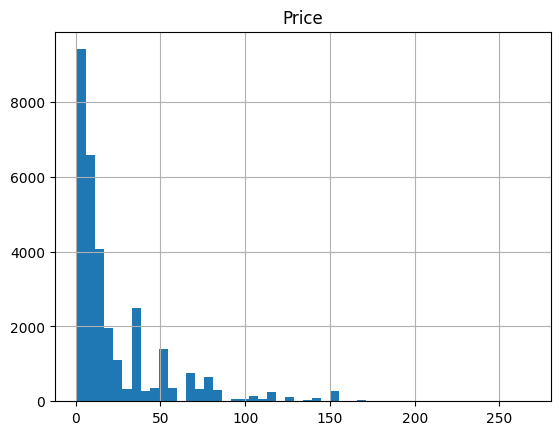

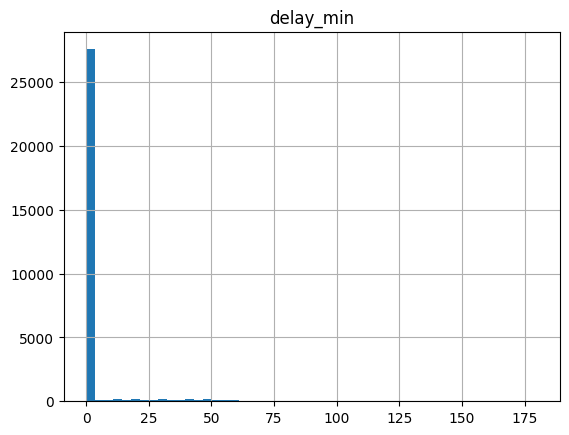

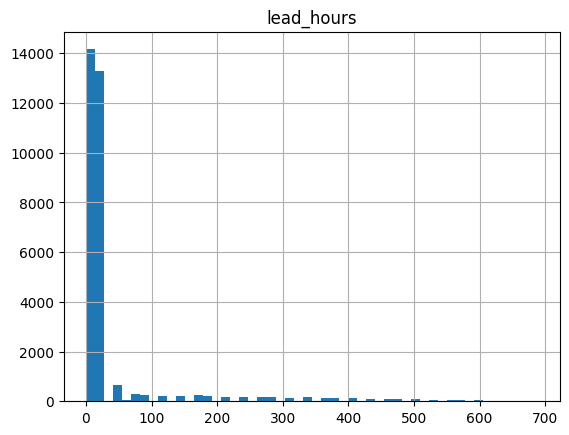

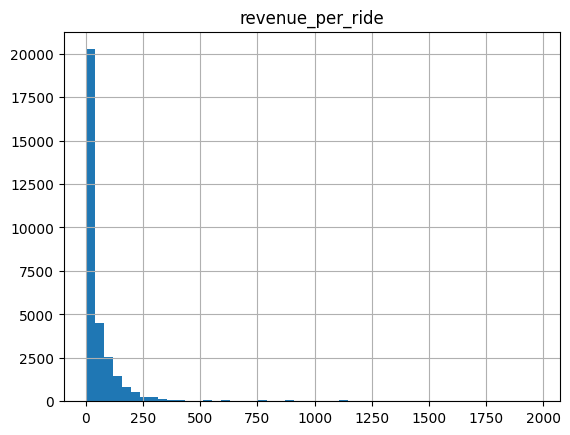

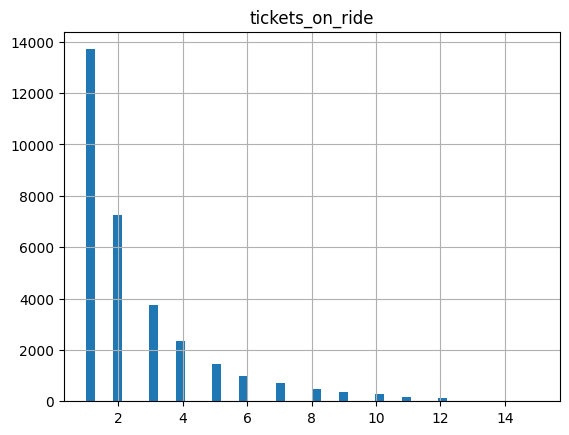

In [193]:
skewed = ["Price", "delay_min", "lead_hours", "revenue_per_ride", "tickets_on_ride"]

for c in skewed:
    df[c].hist(bins=50)
    plt.title(c)
    plt.show()

In [194]:
for c in ["Price", "lead_hours", "revenue_per_ride", "tickets_on_ride"]:
    df[c + "_log"] = np.log1p(df[c])

log_cols = ["Price_log", "lead_hours_log", "revenue_per_ride_log", "tickets_on_ride_log"]
print(df[log_cols].skew().round(2))

Price_log               0.43
lead_hours_log          0.52
revenue_per_ride_log    0.46
tickets_on_ride_log     0.94
dtype: float64


In [195]:
delayed = df[df["Journey Status"] == "Delayed"]["delay_min"]

print("raw  :", round(delayed.skew(), 2))
print("log1p:", round(np.log1p(delayed).skew(), 2))
print("sqrt :", round(np.sqrt(delayed).skew(), 2))

df["delay_sqrt"] = np.sqrt(df["delay_min"])

raw  : 1.94
log1p: -0.99
sqrt : 0.55


Skewness was checked on all numeric columns. Price (2.47), lead time (3.69), revenue per ride (5.73) and tickets per ride (2.02) were strongly right-skewed and were reduced with a log1p transform (to 0.43, 0.52, 0.46 and 0.94). Delay (6.62) is dominated by zeros for on-time journeys, so the transform was assessed on delayed journeys only, where a square root worked better (skew from 1.94 to 0.55) than a log (-0.99). Transformed values were stored in new columns and the originals were left unchanged. Hour and month are symmetric and were not transformed.

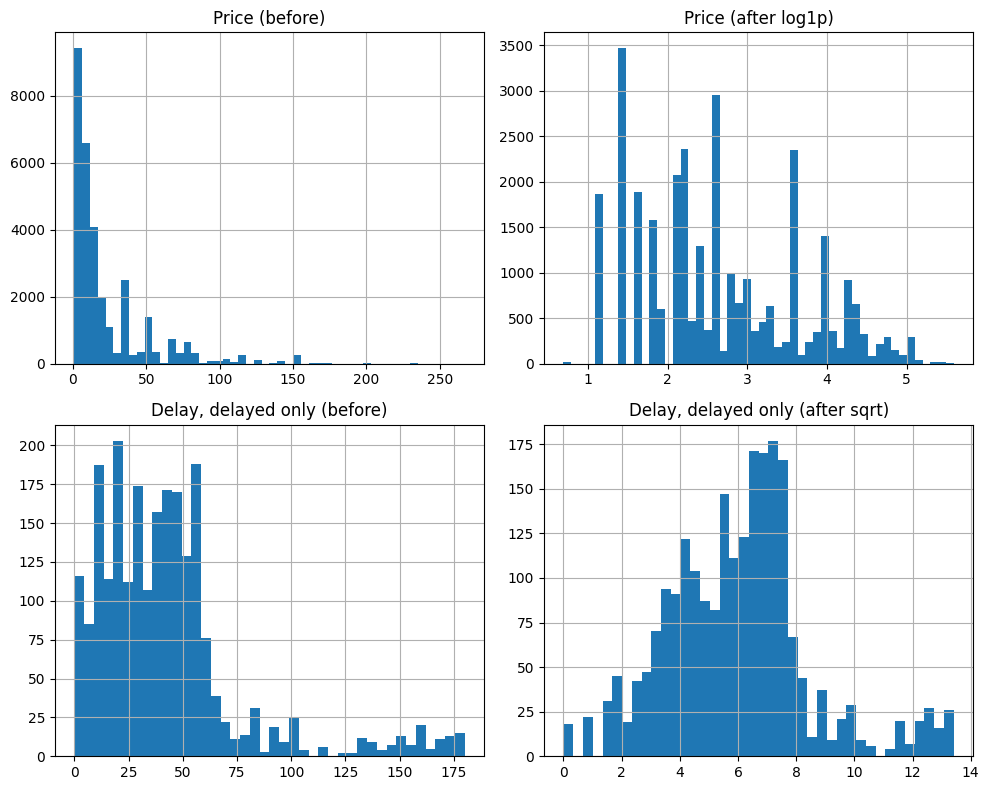

In [196]:
fig, ax = plt.subplots(2, 2, figsize=(10, 8))

df["Price"].hist(bins=50, ax=ax[0, 0]);      ax[0, 0].set_title("Price (before)")
df["Price_log"].hist(bins=50, ax=ax[0, 1]);  ax[0, 1].set_title("Price (after log1p)")

delayed_raw = df[df["Journey Status"] == "Delayed"]["delay_min"]
delayed_raw.hist(bins=40, ax=ax[1, 0]);           ax[1, 0].set_title("Delay, delayed only (before)")
np.sqrt(delayed_raw).hist(bins=40, ax=ax[1, 1]);  ax[1, 1].set_title("Delay, delayed only (after sqrt)")

plt.tight_layout()
plt.show()

In [197]:
def encode_categorical(df, method="label", target_col=None):
    """
    Encode categorical columns in the DataFrame.

    Parameters:
    - df: pandas DataFrame
    - method: str, encoding method ("label" or "onehot")
    - target_col: str, name of the target column for label encoding (optional)

    Returns:
    - df_encoded: pandas DataFrame with encoded categorical columns
    """
    df_encoded = df.copy()
    
    if method == "label":
        le = LabelEncoder()
        for col in df_encoded.select_dtypes(include="object").columns:
            if col != target_col:
                df_encoded[col] = le.fit_transform(df_encoded[col])
    
    elif method == "onehot":
        df_encoded = pd.get_dummies(df_encoded, drop_first=True)

    elif method == "frequency":
        for col in df_encoded.select_dtypes(include="object").columns:
            freq = df_encoded[col].value_counts(normalize=True)
            df_encoded[col] = df_encoded[col].map(freq)
    
    else:
        raise ValueError("Invalid encoding method. Choose 'label' or 'onehot' or 'frequency'.")
    
    return df_encoded

In [198]:
cat_cols = ["Purchase Type", "Payment Method", "Railcard", "Ticket Type",
            "Journey Status", "Reason for Delay",
            "Departure Station", "Arrival Destination", "day_of_week"]

df_enc = df[cat_cols + ["Refund Request", "Price"]].copy()
df_enc["Refund Request"] = df_enc["Refund Request"].map({"No": 0, "Yes": 1})

df_enc = encode_categorical(df_enc, method="frequency", target_col="Refund Request")

print(df_enc.shape)
print(df_enc.columns.tolist())

(31653, 11)
['Purchase Type', 'Payment Method', 'Railcard', 'Ticket Type', 'Journey Status', 'Reason for Delay', 'Departure Station', 'Arrival Destination', 'day_of_week', 'Refund Request', 'Price']
